<a href="https://colab.research.google.com/github/preethikris/BMSCE-DATA-VISUALIZATION/blob/main/Data_Visulization_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# ==========================================
# TASK 5: Spatial & Demographic Analysis (Google Colab)
# Dataset: UCI Adult Census Income Dataset (Direct URL)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
# 1. Load UCI Census dataset directly (treating '?' as NaN)
census_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
census_cols = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]
df_census = pd.read_csv(
    census_url,
    names=census_cols,
    na_values=["?"],
    skipinitialspace=True
)

print("Missing Values Before Cleaning:\n", df_census.isnull().sum()[df_census.isnull().sum() > 0], "\n")

Missing Values Before Cleaning:
 workclass         1836
occupation        1843
native_country     583
dtype: int64 



In [3]:
# 2. Handle Missing Values (Mode imputation for categorical fields)
for col in ["workclass", "occupation", "native_country"]:
    df_census[col] = df_census[col].fillna(df_census[col].mode()[0])

print("Missing Values After Cleaning:", df_census.isnull().sum().sum())

Missing Values After Cleaning: 0


In [4]:
# 3. Normalize Numerical Fields (Min-Max [0, 1] and Z-Score Standardization)
num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
minmax = MinMaxScaler()
zscore = StandardScaler()

df_minmax = pd.DataFrame(
    minmax.fit_transform(df_census[num_cols]),
    columns=[f"{c}_minmax" for c in num_cols]
)
df_zscore = pd.DataFrame(
    zscore.fit_transform(df_census[num_cols]),
    columns=[f"{c}_zscore" for c in num_cols]
)
df_clean = pd.concat([df_census, df_minmax, df_zscore], axis=1)
df_clean["high_income_flag"] = (df_clean["income"] == ">50K").astype(int)

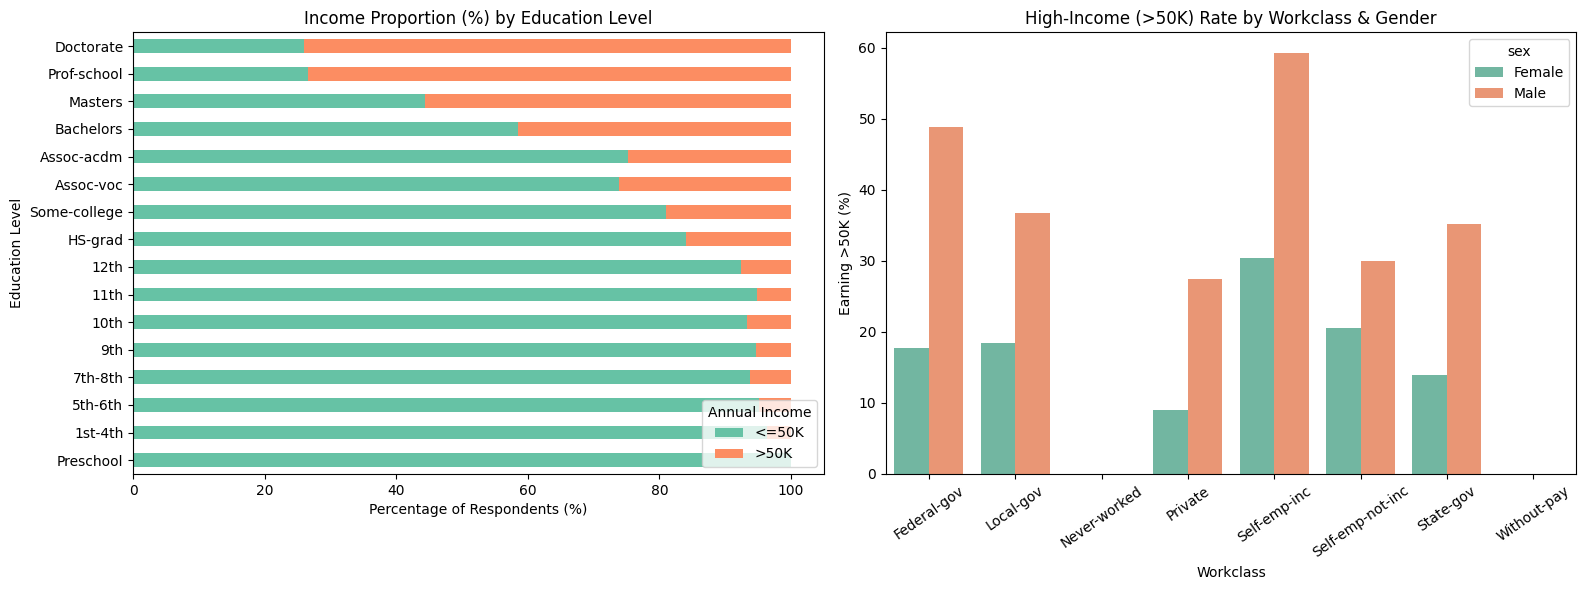

In [5]:
# 4. Demographic Charts: Income Proportions by Education & Gender
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Education vs Income (Ordered by years of education)
edu_order = (
    df_clean.groupby("education")["education_num"]
    .mean().sort_values().index
)
edu_ct = pd.crosstab(df_clean["education"], df_clean["income"], normalize="index").loc[edu_order] * 100
edu_ct.plot(kind="barh", stacked=True, color=["#66c2a5", "#fc8d62"], ax=axes[0])
axes[0].set_title("Income Proportion (%) by Education Level")
axes[0].set_xlabel("Percentage of Respondents (%)")
axes[0].set_ylabel("Education Level")
axes[0].legend(title="Annual Income", loc="lower right")

# Gender & Workclass High-Income (>50K) Rate
sex_work = (
    df_clean.groupby(["workclass", "sex"])["high_income_flag"]
    .mean().reset_index()
)
sex_work["high_income_pct"] = sex_work["high_income_flag"] * 100
sns.barplot(
    data=sex_work, x="workclass", y="high_income_pct", hue="sex",
    palette="Set2", ax=axes[1]
)
axes[1].set_title("High-Income (>50K) Rate by Workclass & Gender")
axes[1].set_xlabel("Workclass")
axes[1].set_ylabel("Earning >50K (%)")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

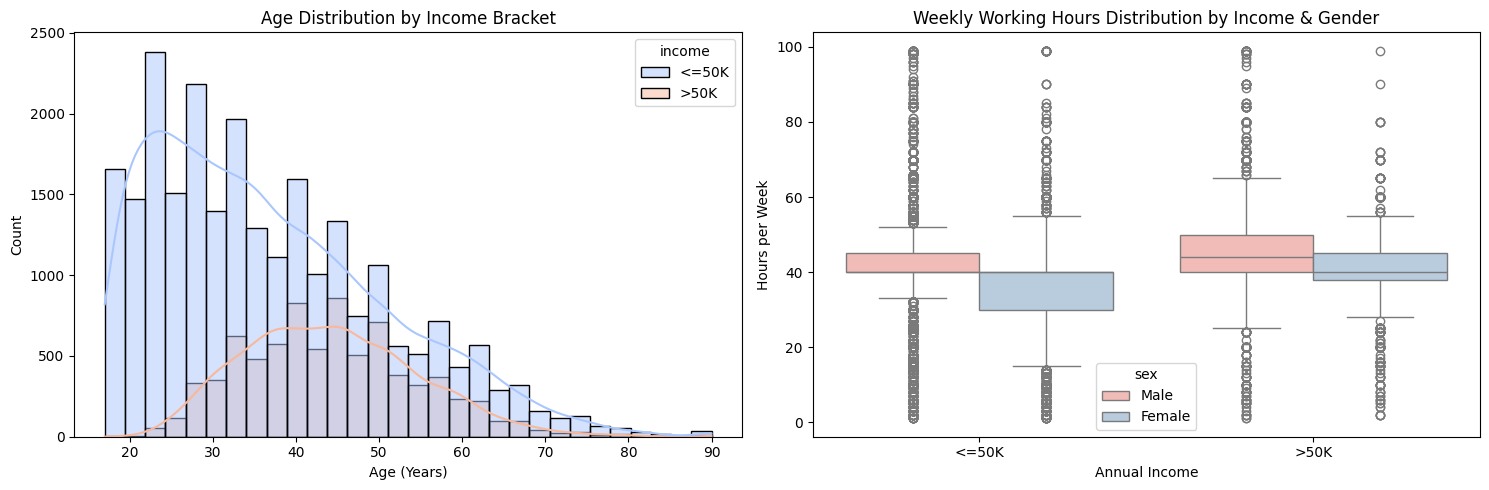

In [6]:
# 5. Distribution Plots: Age & Weekly Working Hours by Income Class
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df_clean, x="age", hue="income", kde=True,
    bins=30, palette="coolwarm", alpha=0.5, ax=axes[0]
)
axes[0].set_title("Age Distribution by Income Bracket")
axes[0].set_xlabel("Age (Years)")

sns.boxplot(
    data=df_clean, x="income", y="hours_per_week",
    hue="sex", palette="Pastel1", ax=axes[1]
)
axes[1].set_title("Weekly Working Hours Distribution by Income & Gender")
axes[1].set_xlabel("Annual Income")
axes[1].set_ylabel("Hours per Week")

plt.tight_layout()
plt.show()

In [7]:
# 6. Hierarchical Treemap (Gender -> Education -> Income Bracket)
treemap_df = (
    df_clean.groupby(["sex", "education", "income"])
    .size().reset_index(name="count")
)
fig_treemap = px.treemap(
    treemap_df,
    path=[px.Constant("Total Census Sample"), "sex", "education", "income"],
    values="count",
    color="income",
    color_discrete_map={"(?)": "#lightgrey", "<=50K": "#4C78A8", ">50K": "#F58518"},
    title="Demographic Treemap: Gender → Education Level → Income Bracket"
)
fig_treemap.update_traces(textinfo="label+value+percent parent")
fig_treemap.show()


In [8]:
# 7. Interactive Geospatial Map (Choropleth by Native Country)
country_name_map = {
    "United-States": "United States",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "South": "South Korea",
    "Hong": "Hong Kong",
    "Trinadad&Tobago": "Trinidad and Tobago",
    "Columbia": "Colombia",
    "Outlying-US(Guam-USVI-etc)": "Guam",
    "Yugoslavia": "Serbia",
    "Holand-Netherlands": "Netherlands"
}
df_clean["country_clean"] = df_clean["native_country"].replace(country_name_map)

geo_df = (
    df_clean.groupby("country_clean")
    .agg(
        respondents=("income", "count"),
        high_income_pct=("high_income_flag", lambda s: round(s.mean() * 100, 2)),
        avg_hours=("hours_per_week", lambda s: round(s.mean(), 1)),
        avg_edu_years=("education_num", lambda s: round(s.mean(), 1))
    )
    .reset_index()
)

fig_map = px.choropleth(
    geo_df,
    locations="country_clean",
    locationmode="country names",
    color="high_income_pct",
    hover_name="country_clean",
    hover_data={"respondents": True, "avg_hours": True, "avg_edu_years": True, "country_clean": False},
    color_continuous_scale="Viridis",
    title="Interactive Geospatial Map: High-Income (>50K %) & Demographics by Native Country"
)
fig_map.update_layout(geo=dict(showframe=False, showcoastlines=True))
fig_map.show()